# 05 · Explainability

Two views:

1. **SHAP** on the Isolation Forest: which features push a transfer toward "anomalous".
2. **Reason codes** shown to analysts in the Fraud Desk: model-agnostic, computed from how far each
   feature sits on the suspicious side of normal (robust z-scores), plus any hard rule that fired.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kronos_ml.config import load_config, DATA_DIR, MODELS_DIR, REPORT_DIR
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
cfg = load_config()

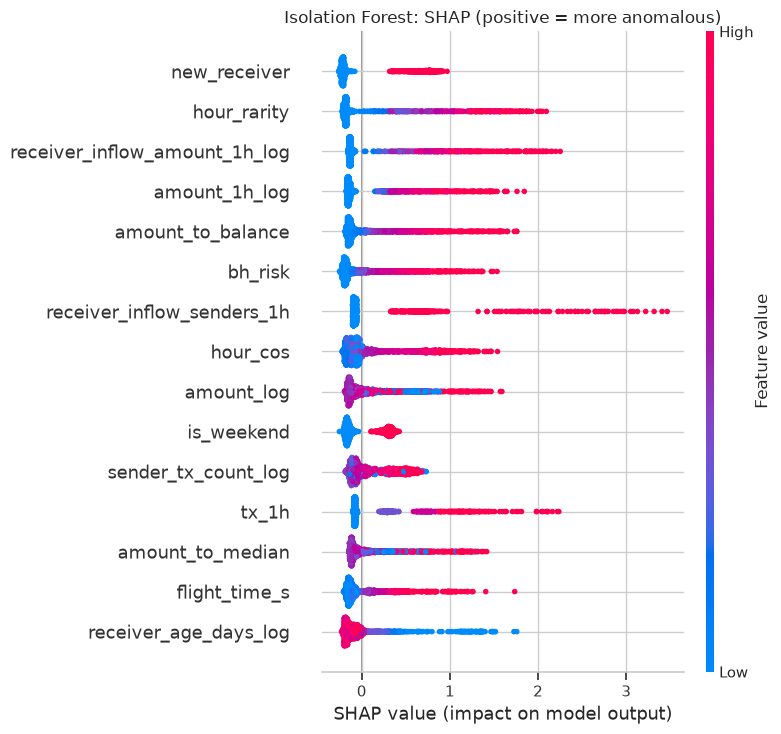

In [2]:
import joblib, shap
from kronos_ml.models.train import load_features, split
from kronos_ml.features.build import FEATURES
from kronos_ml.explain import shap_values
parts = split(load_features(), cfg)
test = parts["test"]
iforest = joblib.load(MODELS_DIR / "isolation_forest.joblib")
sample = pd.concat([test[test.is_fraud == 1].sample(400, random_state=0), test[test.is_fraud == 0].sample(1600, random_state=0)])
sv, Xs = shap_values(iforest, sample)
shap.summary_plot(sv, pd.DataFrame(Xs, columns=FEATURES), show=False, max_display=15)
plt.title("Isolation Forest: SHAP (positive = more anomalous)"); plt.tight_layout()

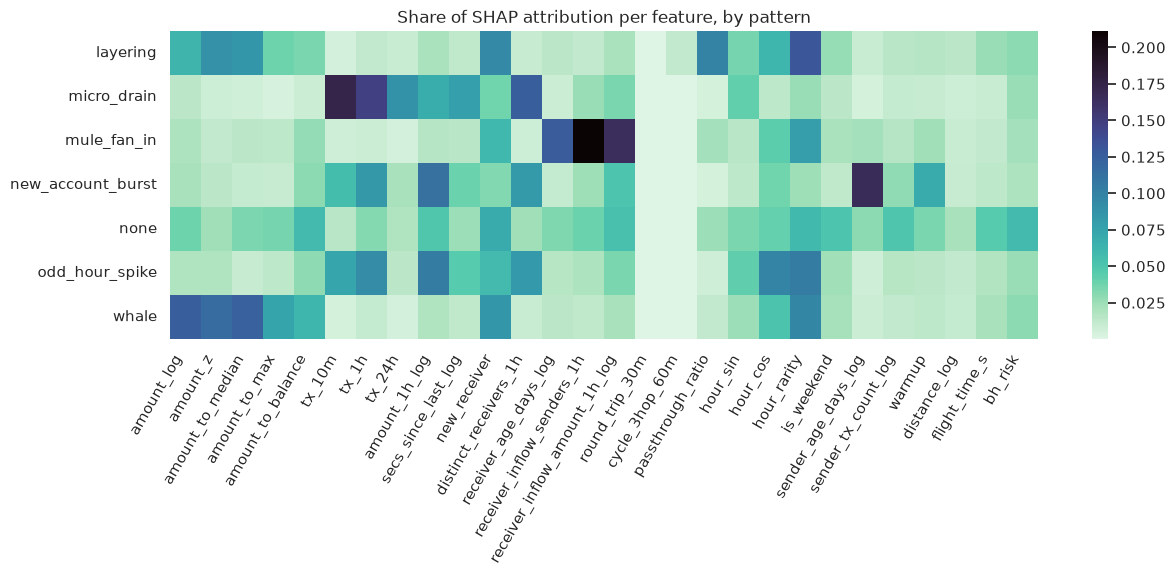

In [3]:
imp = pd.DataFrame(np.abs(sv), columns=FEATURES).groupby(sample.fraud_type.to_numpy()).mean()
plt.figure(figsize=(14, 4))
sns.heatmap(imp.div(imp.sum(axis=1), axis=0), cmap="mako_r")
plt.title("Share of SHAP attribution per feature, by pattern"); plt.xticks(rotation=60, ha="right");

### Reason codes for one example of each pattern (what the analyst sees)

In [4]:
from kronos_ml.rules import rule_score_one
bundle = joblib.load(MODELS_DIR / "deployed.joblib")
rows = []
for pattern in ["micro_drain", "whale", "odd_hour_spike", "layering", "mule_fan_in", "new_account_burst", "none"]:
    cand = test[test.fraud_type == pattern]
    r = cand.iloc[int(bundle["detector"].raw(cand).argmax())] if pattern != "none" else cand.iloc[0]
    feats = r[FEATURES].to_dict()
    score = max(float(bundle["calibrator"](bundle["detector"].raw(pd.DataFrame([feats]))[0])), rule_score_one(feats)[0])
    reasons = bundle["explainer"].explain(feats, rule_score_one(feats)[1])
    rows.append({"pattern": pattern, "score": round(score, 2), "reasons": " | ".join(x["text"] for x in reasons)})
pd.DataFrame(rows)

,pattern,score,reasons
0,micro_drain,1.00,rule: 8+ transfers in 10 minutes | 46 transfer...
1,whale,0.96,rule: amount 20x+ the sender's usual | amount ...
2,odd_hour_spike,0.96,7 transfers in the last hour | 5 different rec...
3,layering,0.95,forwards money received in the last 30 minutes...
4,mule_fan_in,0.96,receiver collected money from 12 senders in th...
5,new_account_burst,0.97,12 transfers in the last hour | 7 different re...
6,none,0.39,unusually long route | first payment to this r...


The reason codes agree with SHAP on the big drivers (amount, velocity, new payee, inflow to the receiver,
account age) while staying cheap enough to compute on every live transfer (about a millisecond).